# Zachary Weed

In [9]:
import os

os.environ["STABILITY_KEY"] = ""

In [10]:
import sys, platform
print(sys.executable)
print(sys.version)
print(platform.platform(), platform.machine())

/opt/anaconda3/envs/skenv312/bin/python
3.12.12 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 20:07:49) [Clang 20.1.8 ]
macOS-14.7.6-arm64-arm-64bit arm64


# [Problem 1] - Working With Stability-SDK

## Problem Statement **Problem 1.**
Follow instructions on https://github.com/Stability-AI/stability-sdk and install `stability-sdk`. Please test your installation using commmand interface prompt. Submit a short request consisting of 3-4 words. Capture the process and all employed commands. Capture the result. You have a limited number of free requests. You are welcome to use any Web interfaces offered by Stability.ai to accomplish this task.

In [11]:
pip install stability-sdk

Note: you may need to restart the kernel to use updated packages.


In [16]:
import sys

!{sys.executable} -m stability_sdk generate -W 1024 -H 1024 "an ethereal bunch of flies, pigs, pudding, foxes, cats, and dogs at a luau"

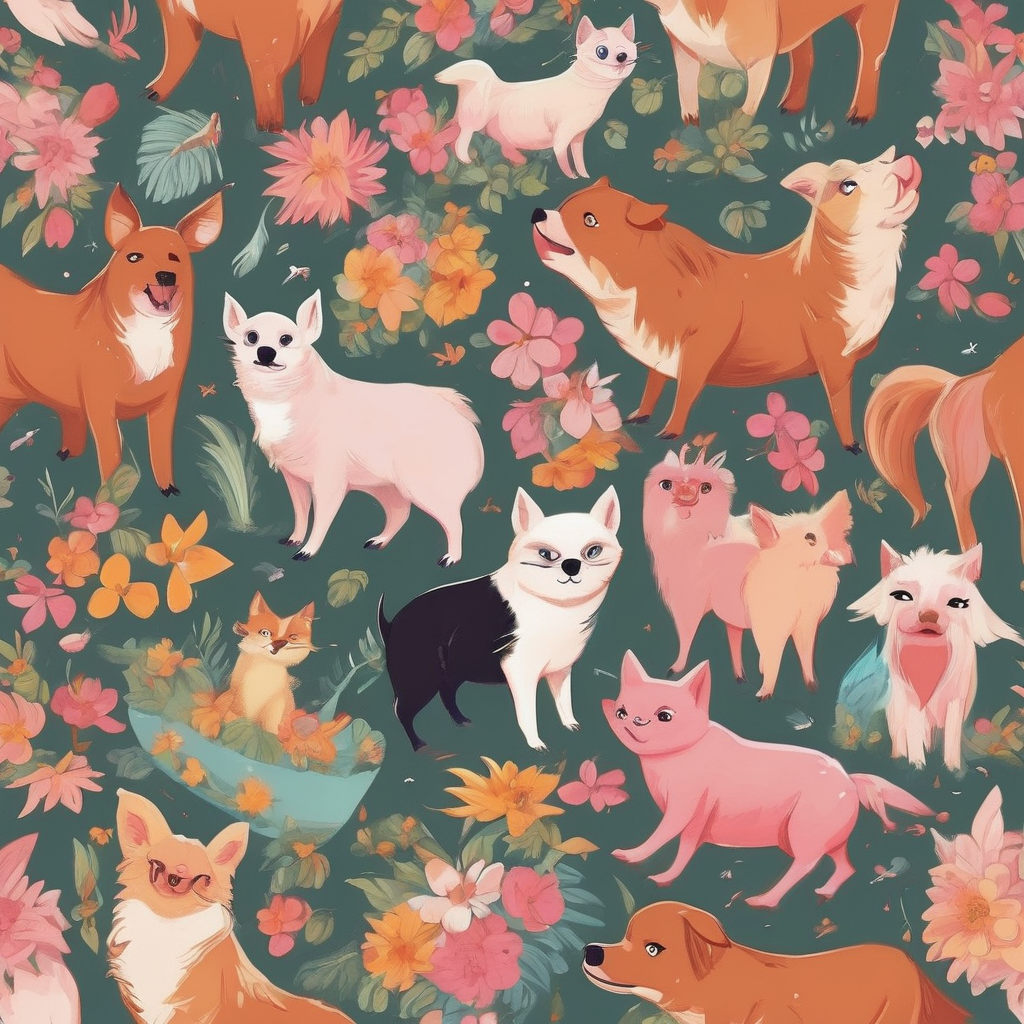

# [Problem 2] - Training Diffusion Model on MNIST

## Problem Statement **Problem 2.**
Starting with the code in notebook `04_diffusion_models.ipynb` train your diffusion model with Fashion MNIST images. Run the model with the default scheduler. Demonstrate that it can generate a recognizable set of images.

## Description

Writing these here because it helps make sense of what we are working with. We are working with a Diffusion model, based upon UNet, that iteratively reduces noise from a given image until some version of an image is reached. My understanding is it is specialized Convolutional Neural Network, in that it convolves an image as it reduces noise, **though** it is considered far faster than a traditional CNN.. 

What we are working with specifically is a UNet model. What makes this model different is we are working with the concept of Down Blocks, which are an important element of UNet architecture.

Within the concept of Down Blocks, as data is convolved, the high-quality data is preserved and re-used as it makes its way to the decoder. This is different from Convolutional Neural Networks that tend to downsample all data, at the sake of quality upon decoding.

The closest thing I can relate them with is VBR Audio encoding (eg V0, Vorbis, etc.), where information that humans want to hear is kept at a higher sample rate, while other content is downsampled, as a means of preserving high quality audio, and benefitting storage capacity. Having said that, a primary element of how this is helpful in Diffusion models is the quality of the images produced.

Another note: I did have to modify `image_size` because the expansion of images in the Attention Block was resulting in high memory allocations (81GB).

## Noise Scheduler
My understanding of the inclusion of a noise scheduler, is we define a function that provides a way of injecting noise into an image along some set of discrete points that are timesteps. Having said that, we had to make some modification to the `UNet` class. Specifically:

- building a multi_layer_perceptron built on given time_dimensions
- build an additional upsampling and downsampling stack of Linear layers with given dimensions
- integrate the time dimension at each denoising step

My understanding is, if we think about gradients, it is akin with providing the model with a way of always knowing which direction to go at each step of denoising (i.e. most optimal denoising direction), given the additional dimension of time.

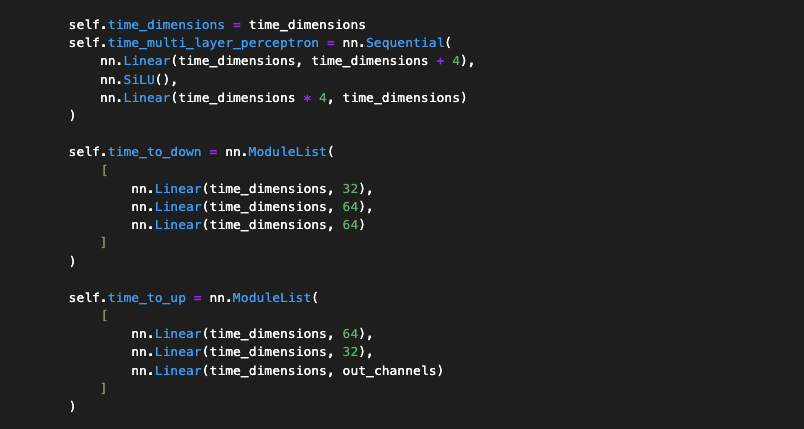

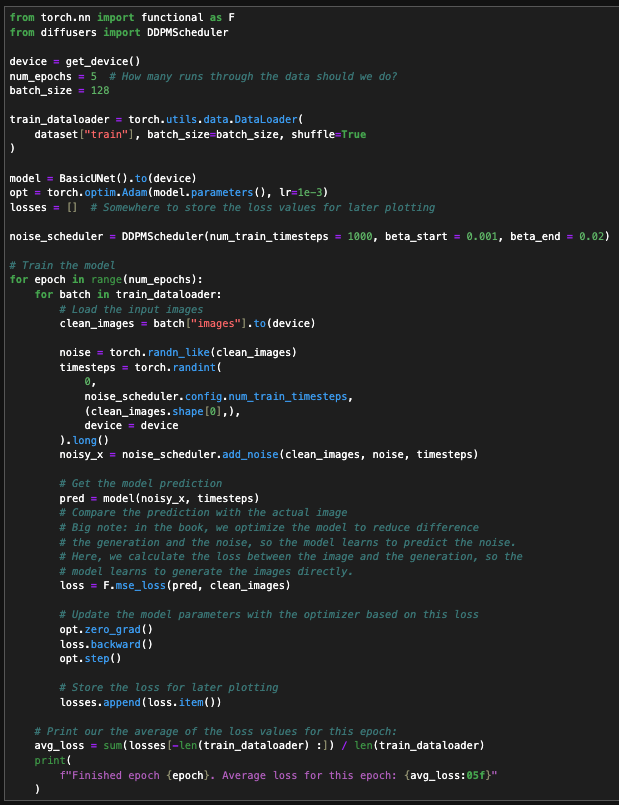


## Results

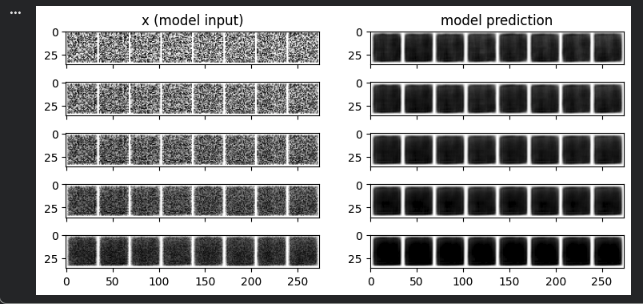

The results are relatively unrecognizable.

# [Problem 3] - High, Low Beta schedulers & Frechet Inception Distance (FID)

## Problem Statement **Problem 3.**
Examine behavior of your model from problem 2 with two differnt schedulers: low beta and high beta schedulers. Make a visual comparison of the difference in the quality of generated image, if any. Search through the literature and identify a mechanism to compare those images "mechanically". Use the original Fashion MNIST images as references. If your conclusion is negative in the sense that there is no convenient open source tool fo this task, please state so. You might wan to try your own "mechanical" comparison routine.

## Visual Comparison of High & Low Beta Schedulers

### Description
How this works is at each timestep, as we provided the time dimension at each step of the noising process, we can introduce noise. Beta defines how much noise is actualy generated, and thus High Beta would introduces a higher amount of noise than low beta. We were able to introduce this into the mix by defining a `DDPMScheduler`, and adjusting with a wider range for Beta-High and vice versa for Beta-Low.

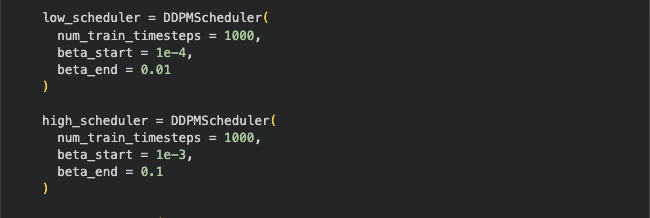

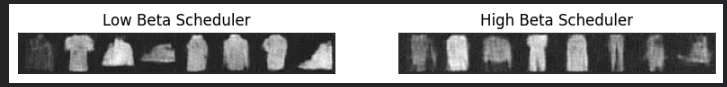

## Inclusion of Frechet Inception Distance (FID) 
We use the Frechet Inception Distance to determine how close to the original the noisified images are

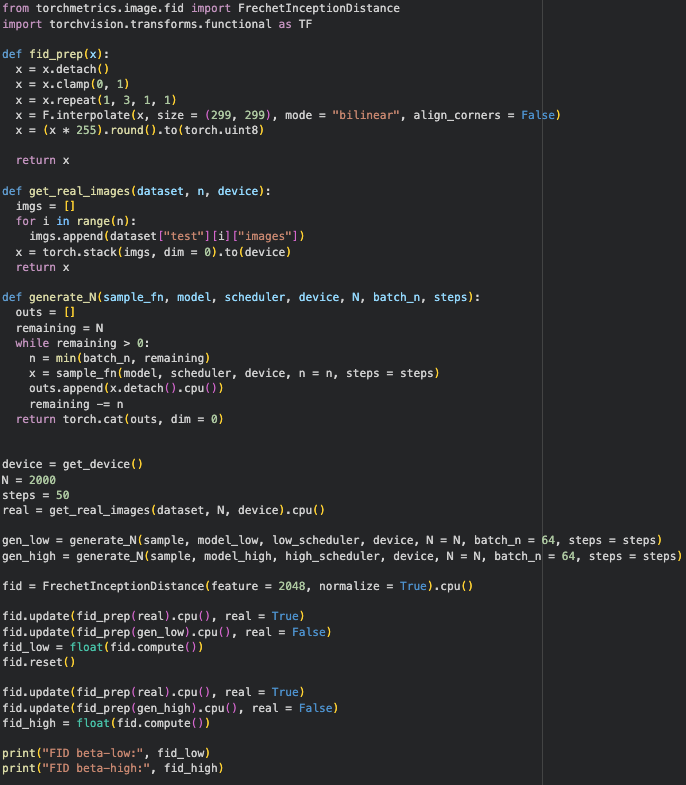

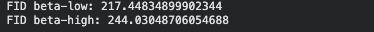

Resulting from the use of Frechet Inception Distance, we can find that a visual identification is similar, in that there is less noise in the Beta-Low scheduler

# [Problem 4] - Stable Diffusion VAE

## Problem Statement **Problem 4.**
Please use StableDiffusionPipeline and AutencoderKL with a fine-tuned VAE decoder from HuggingFace pre-trained model, as illustrated by notebook: `05_stable_diffusion.ipynb`, and provide a positive prompt, a negative prompt, inference steps, set a random seed, and change the size, and guidance scale (similar to what can be done with Stable Diffusion WebUI to generate the image as you wish.

## Description
The primary work associated with this involved identifying "positive" and "negative" prompts, as what is wanted (the positive) and what is not wanted (the negative) as a means of guiding the Stable Diffusion model through building an image from what is orignally pure noise.

## Positive Prompt & Negative Prompt
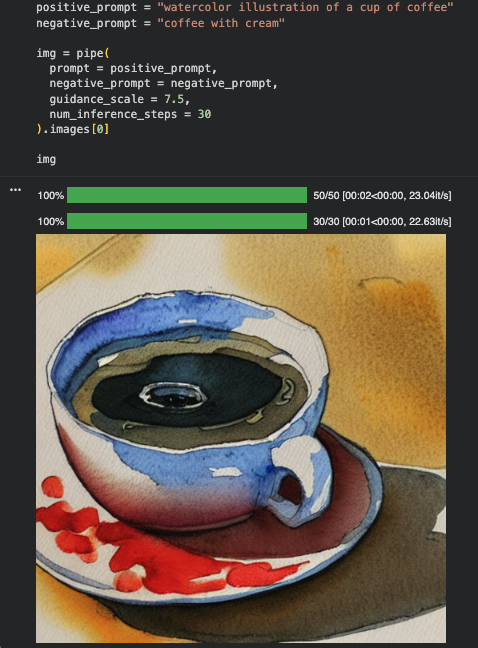

In essence we say like "this is what I want and that is what I do not want", representing positive and negative, respectively.

# [Problem 5] - Training on MNIST

## Problem Statement **Problem 5.**
Start with the code in notebook `05_stable_diffusion.ipynb` and train a conditioned model on MNIST handwritten images. Demonstrate that you can ask the model to generate the number 5 and the number 7.

## Description
The primary changes here involved filtering the original data to only 5 & 7. Changes were relatively straightforward, as much of the code was already existing. I did remove the horizontal flip because the data was relatively grainy in scenarios where it was not.

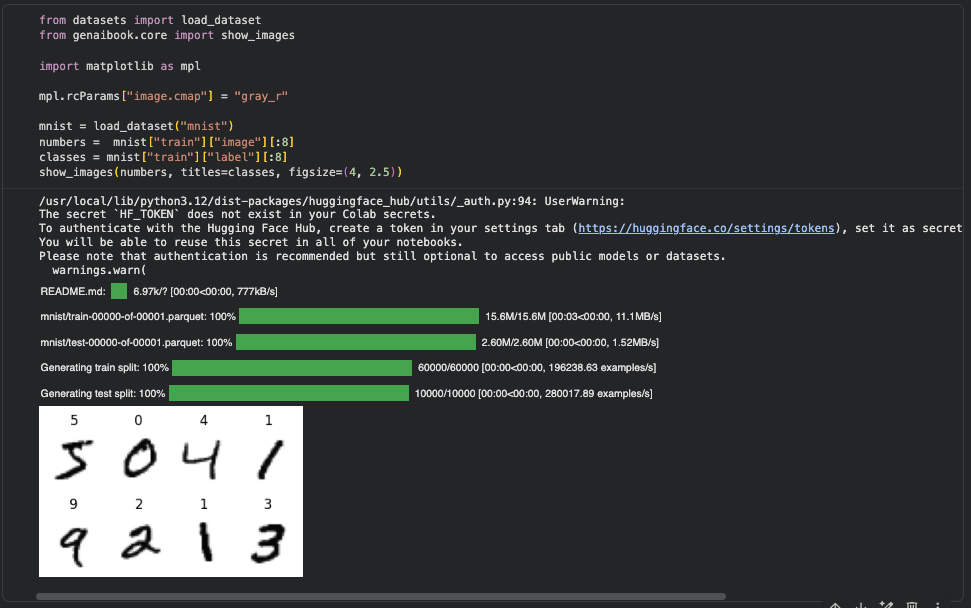
Renaming everything so it is MNIST specific

## Producing 5 & 7
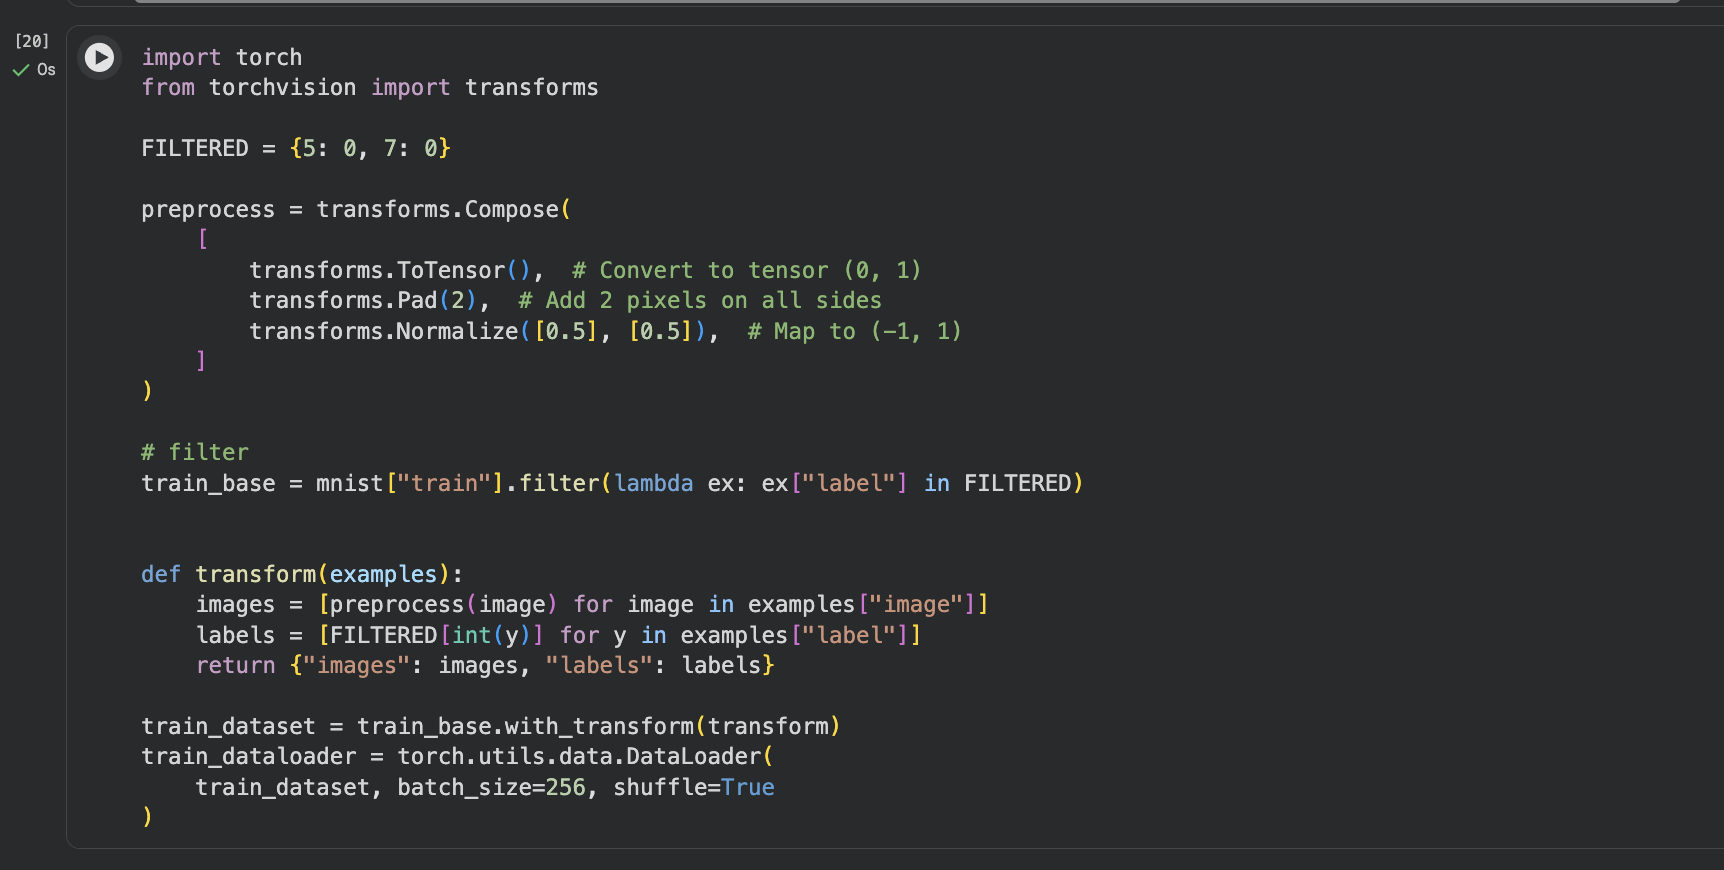
Filtering to only 5 & 7

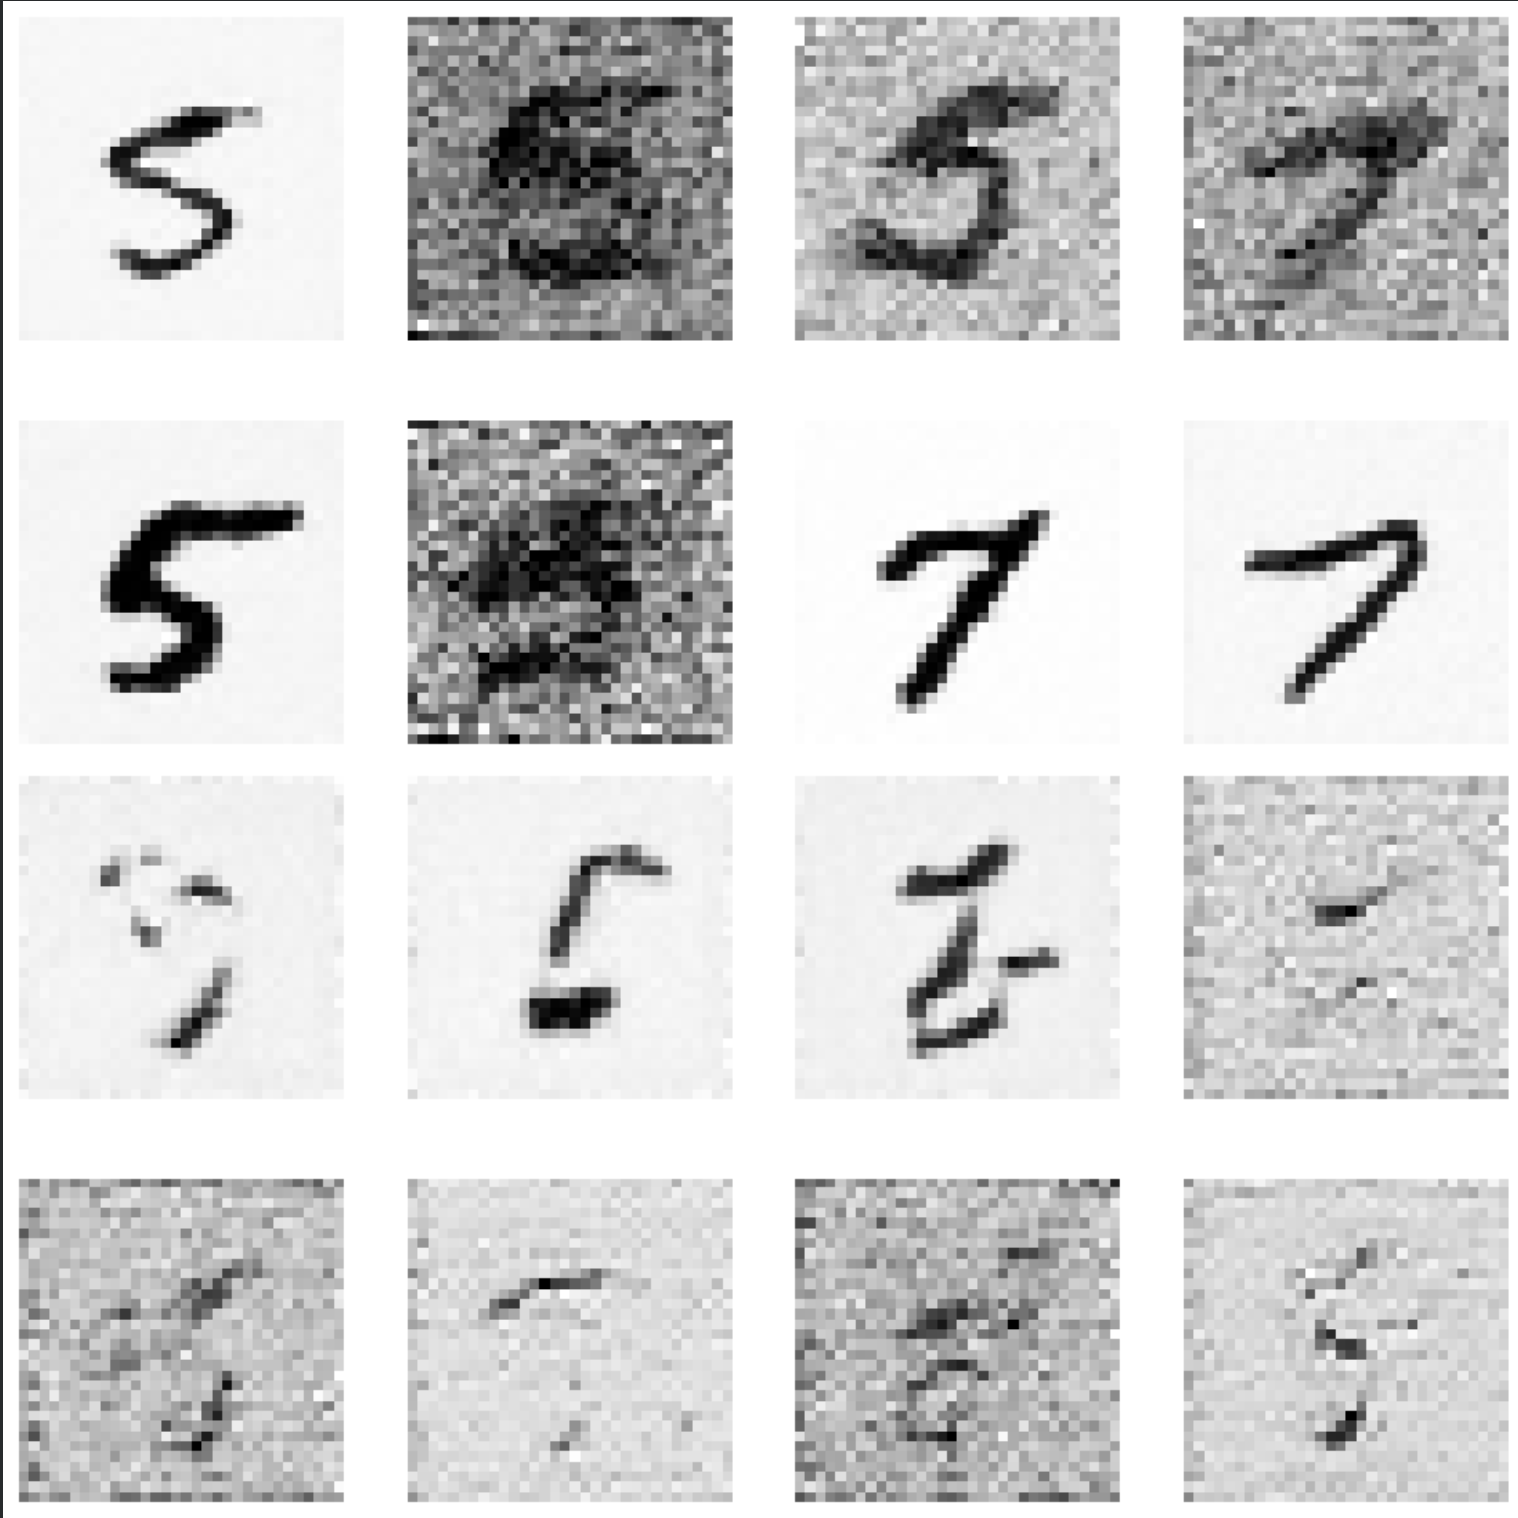

The primary change here involved filtering from the original dataset to the numbers 5 & 7